In [173]:
import sys, os
import numpy as np
import glob
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import h5py
from netCDF4 import Dataset
from scipy.interpolate import griddata
from pathlib import Path
from matplotlib.patches import Patch
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FormatStrFormatter
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.mplot3d import proj3d


# sys.path.insert(0, r"B:\publication_1")
import Read_RTM as ReadEC
import Find_Overpass_Info as Find_Overpass_Info

# from Make_RTM import Calc3DBufferSize

In [81]:

def Calc3DBufferSize(ia, iacr, which_buffer, sza_deg, phi0_deg):
    WANT_PRINTS = False
    # BG: Decide to use my buffer, not dynamic buffer!
    if which_buffer == 0:   along_dim, across_dim =  0,  0 # ( 1, 1) comp-domain  MCIPA 
    elif which_buffer == 1: along_dim, across_dim =  2,  2 # ( 5, 5) comp-domain  Test Buffer
    elif which_buffer == 2: along_dim, across_dim = 10, 10 # (21,21) comp-domain  ~BBR +  5 pixels-buffer
    elif which_buffer == 3: along_dim, across_dim = 20, 20 # (41,41) comp-domain  ~BBR + 35 pixels-buffer
    elif which_buffer == 4:  # Sun-depenent buffer
        cloud_hight_estimate = 10 # Upper bound clouds 
        
        factor_across = abs(np.sin(np.deg2rad(phi0_deg)))
        factor_along  = abs(np.cos(np.deg2rad(phi0_deg)))
        print(f"factor_across = {factor_across:.2f}    factor_along = {factor_along:.2f}")
        
        factor_projected_length = abs(cloud_hight_estimate * np.tan(np.deg2rad(sza_deg)))
        print(f"factor_projected_length = {factor_projected_length:.2f}")

        along_dim  = int(factor_along * factor_projected_length)
        across_dim = int(factor_across * factor_projected_length)

        print(f"along_dim = {along_dim} across_dim = {across_dim}")
        print("\n\n")

    if ia is None or iacr is None:
        ialongs, iacrosses = np.array([]), np.array([])
    else:
        ialongs = np.arange(ia-along_dim, ia+along_dim+1)
        iacrosses = np.arange(iacr-across_dim, iacr+across_dim+1)
    
    Nx = 2*across_dim+1
    Ny = 2*along_dim+1


    return Nx, Ny, iacrosses, ialongs




def pdeg2km(p):
    latfact = 111.32
    p0 = latfact*p[0]/1000
    lonfact = 40075 * np.cos(np.deg2rad( p[1] )) / 360
    p1 = latfact*p[1]/1000
    return (p0,p1)


In [58]:

FONTSIZE=15
INFOSIZE=10
FIGSIZE=(10,10)
cmap = plt.get_cmap('viridis') 
cmap = plt.get_cmap('inferno') 
# cmap = plt.get_cmap('coolwarm')
librad_type         = 'SWIA'
version_identifier  = 'v01'
source_str          = 'solar'

def Read_EC_data(WANT_3D, WANT_EUP, ial=None, iacr=None):
    ProductPathRTM = Path(r"B:\publication_1\RESULTS_TEST")
   
    # Distinguish minor modifications to .nc files
    additional_spesifications = '_SINGLE_CLOUD' 
    # additional_spesifications = '_AllLevels_TEST_5x5'

    if WANT_EUP:    additional_spesifications += '_TOA'     
    else:           additional_spesifications += '_SUR'        
    # Pick the correct model version
    librad_version = 'montecarlo_3D' if WANT_3D else 'disort_1D'

    
    # Download libRadtran runs
    Product = (
        'libRad_' + 
        version_identifier  + '_' +
        librad_version      + '_' +
        source_str          + 
        additional_spesifications
                            + '.nc'
    )
    ProductPath = ProductPathRTM



    ProductFile = os.path.join(ProductPath, Product)
    print("Searching for libRadtran file:", ProductFile)
    # ###################################

    try: 
        ProductFile = sorted(glob.glob(ProductFile))[0]    
        libRad = ReadEC.Scene(Name="Single Cloud")
        libRad.ReadEarthCAREh5(ProductFile)
        libRad.SetExtent()
        print("Found libRadtran file:", ProductFile)
    except IndexError: 
        print(f"\n     Cannot find product {Product}") 

    



    return libRad
        

### 3D Plot

In [ ]:

def plot_3D(libRad, ial, iacr, title, h_max=10, fig_elev=90, which_buffer=2, WANT_COMPASS=False, sza_deg=45, phi0_deg=45):
    fig         = plt.figure(figsize=FIGSIZE)
    ax          = fig.add_subplot(111, projection="3d", computed_zorder=False) # zorder to put surface-flux below others
    xlabel      = "x"; xlabel_specs = r" [km]"
    ylabel      = "y"; ylabel_specs = r" [km]"
    zlabel      = "Height"; zlabel_specs = r" [km]"
    handles     = []
    color_iwc   = "lightskyblue"
    color_lwc   = "white" #"lightgrey" #"whitesmoke"

    azimuth_offset = 30

   
    ice_cmap = LinearSegmentedColormap.from_list("ice_turquoise",["#F7FFFF", "#CCF7F4", "#8DE3D8", "#4CC7C3", "#1A9AA3"])
    water_cmap = LinearSegmentedColormap.from_list("water_blue", ["#F8FBFF", "#DDEBFF", "#B7D2FF", "#7EA7FF", "#2D5BDB"])
  
    if 'eup' in libRad.fn:   cblabel = r"$F_{\mathrm{TOA}}^{\uparrow}$ [W/m$^2$]"
    else:                    cblabel = r"$F_{\mathrm{SUR}}^{\downarrow}$ [W/m$^2$]"

                                            

    print(libRad.fn, libRad.Name)



    # Construct 3D cloud domain using the SCA
    ########################################################################################
    Nx, Ny, iacrosses, ialongs = Calc3DBufferSize(ial, iacr, which_buffer, sza, phi0)
    Nz = 100
    print(f"len(ialongs) = {len(ialongs)}    len(iacrosses) = {len(iacrosses)}")
    print(f"ialongs = {ialongs}")
    print(f"iacrosses = {iacrosses}")





    # Create grid for plotting
    #############################################################################################
    # Find index for surface index
    h = np.linspace(0, h_max, Nz)
   
    # make edges-array -> ialongs = [10,11,12] -> edges = [10,11,12,13]
    step_x =  iacrosses[1] - iacrosses[0]   # = 1 pixel
    step_y =  ialongs[1]   - ialongs[0]     # = 1 pixel

    x_edges = np.r_[iacrosses, iacrosses[-1] + step_x] - step_x/2
    y_edges = np.r_[ialongs  , ialongs[-1]   + step_y] - step_y/2
    z_edges = np.arange(Nz + 1, dtype=float)

    surface_index = 0
    X, Y = np.meshgrid(x_edges, y_edges, indexing="ij")
    Z = np.full(X.shape, surface_index, dtype=float)

    Xvoxel, Yvoxel, Zvoxel = np.meshgrid(
        x_edges,
        y_edges,
        z_edges,
        indexing="ij",
    )






    # construct liquid cloud for plotting
    # tmpFILE = "tmpTESTING_v1_3155wc3D.dat" if TEST_ARVE_CODE_v1 else "tmpTESTING_v2_3155wc3D.dat" if TEST_MY_NEW_CODE_v2 else "tmpTESTING_v3_1700wc3D.dat"
    # test_name = Product.split("_solar_", 1)[1].split("_Filefjell_SUR.nc", 1)[0]
    # test_name = libRad.fn.split("_solar_", 1)[1].split("_Filefjell_SUR_SINGLE_CLOUD.nc", 1)[0]
    # tmpFILE = f"tmp{test_name}_0{ial}wc3D.dat"

    tmpFILE = f"tmp_{ial:04}_wc3D.dat"
    with open("tmpRTIO/" + tmpFILE, "r") as f:
        next(f)  # Skip first header line
        next(f)  # Skip height line

        lwc_plot = np.full((Nx, Ny, Nz), np.nan)


        for line in f:
            ix, iy, iz, wc, _ = line.split()
            ix = int(ix) - 1
            iy = int(iy) - 1
            iz = int(iz) + surface_index - 1

            if float(wc) != 0.0:
                lwc_plot[ix, iy, iz] = float(wc)

        # True only where cloud values exist
        lwc_mask = np.isfinite(lwc_plot) & (lwc_plot > 0)

    ax.voxels(
        Xvoxel, Yvoxel, Zvoxel,
        lwc_mask,
        facecolors="#A2CDF7",
        alpha=0.7,
        edgecolor=None,
        zorder=3
    )
    handles.append(Patch(facecolor="#A2CDF7", edgecolor="none", label="Water cloud"))
    
    cloud_cells = np.argwhere(lwc_mask)
   
    ix_min, iy_min, iz_min = cloud_cells.min(axis=0)
    ix_max, iy_max, _ = cloud_cells.max(axis=0)

    for x in (x_edges[ix_min], x_edges[ix_max + 1]):
        for y in (y_edges[iy_min], y_edges[iy_max + 1]):
            ax.plot(
                [x, x],
                [y, y],
                [surface_index, z_edges[iz_min]],
                color="black",
                linestyle=":",
                linewidth=1.2,
                zorder=11,
            )





    # Plot libRadtran fluxes
    #########################################################################################
    flux = libRad.solar_eup    # (along, Nx/across-track buffer, Ny/along-track buffer)
    print(np.shape(flux))
    if WANT_3D:
        flux = flux[0,:, :]
    else:
        # Mapping 1D flux to 2D grid
        tmp_flux = np.zeros((len(iacrosses), len(ialongs)))
        for i, ial_ in enumerate(ialongs):
            for j, iac_ in enumerate(iacrosses):
                tmp_flux[j, i] = flux[i*Nx + j]
        flux = tmp_flux
                
    
    flux_min = np.nanmin(flux)
    flux_max = np.nanmax(flux)
    flux_min = 0.0 # Include 0 in colorbar
    # flux_max = 500
    # flux_min = 220
    flux_max = 1000
    norm = Normalize(vmin=flux_min, vmax=flux_max)
    facecolors = cmap(norm(flux))
        
   
    print(f"flux.shape = {flux.shape}")
    surface = ax.plot_surface(
        X,Y,Z,
        facecolors=facecolors,
        # edgecolors="none",
        antialiased=False,
        linewidth=0,
        shade=False,
        zorder=10 if WANT_EUP else 1
    )

    # Colorbar with actual flux values
    mappable = ScalarMappable(norm=norm, cmap=cmap)
    mappable.set_array(flux)
    colorbar = fig.colorbar(
        mappable,
        ax=ax,
        shrink=0.4,      # shorter colorbar
        fraction=0.08,   # thinner colorbar
        # pad=0.02,         # closer to plot
        aspect=15,        # larger = thinner,
    )
    # colorbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
    colorbar.set_label(cblabel, fontsize=INFOSIZE)




    # Plot SZA 
    ###################################################################################################
    print(f"sza = {sza_deg:.0f}°; phi0 = {phi0_deg:.0f}° (rel to north, Clockwise)")
    # Add info to plot
    ax.text2D(
        0.90,0,
        f"SZA = {sza_deg:.1f}°     "+ r"$\phi_0$"+ f" = {phi0_deg:.1f}°",
        transform=ax.transAxes,
        fontsize=INFOSIZE*.8,
        verticalalignment="bottom",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            edgecolor="none",
            alpha=0.8),
    )





    # Add compass
    ###########################################################################################################################
    if WANT_COMPASS:
        # compass = fig.add_axes([0.87, 0.87, 0.05, 0.05])
        compass = ax.inset_axes([1, 0.9, 0.1, 0.1])
        compass.axis("off")

        # Rotate compass with azimuth offset to the compass
        offset = np.deg2rad(azimuth_offset)
        cos_offset, sin_offset = np.cos(offset), np.sin(offset)
        def rotate_xy_offset(x, y):
            return (
                x * cos_offset + y * sin_offset,
                -x * sin_offset + y * cos_offset,
            )

        for label, (x, y) in {"N":(0,1), "S":(0,-1), "W":(-1,0), "E":(1,0)}.items():
            x_rot, y_rot = rotate_xy_offset(x, y)
            compass.annotate("", xy=(x_rot, y_rot), xytext=(0, 0),
                            arrowprops=dict(arrowstyle="->", lw=1))
            compass.text(1.15*x_rot, 1.15*y_rot, label,
                        ha="center", va="center", fontsize=7)
        compass.set(xlim=(-1.4, 1.4), ylim=(-1.4, 1.4), aspect="equal")

        # Add Sun Direction Arrow
        color = "red"
        # sun = ax.inset_axes([1, 0.9, .1, .1])
        # sun.axis("off")

        phi = np.deg2rad(phi0_deg)
        L = 1
        dx, dy = -np.sin(phi), -np.cos(phi)
        dx, dy = dx*L, dy*L
        dx, dy = rotate_xy_offset(dx, dy)
        compass.annotate("", xy=(dx,dy), xytext=(0,0), arrowprops=dict(arrowstyle="->", lw=2, color=color))
        compass.text(dx, dy+.6, r"$\phi_0$ (Sun Azimuth)", ha="left", va="center", color=color)
        compass.set(xlim=(-L,L), ylim=(-L,L), aspect="equal")






    # Plot Settings 
    ####################################################################################################
    ax.set_title(title, fontsize=FONTSIZE)
    ax.set_xlabel(xlabel+xlabel_specs, fontsize=INFOSIZE)
    ax.set_ylabel(ylabel+ylabel_specs, fontsize=INFOSIZE, labelpad=15)
    ax.set_zlabel(zlabel+zlabel_specs, fontsize=INFOSIZE, labelpad=0)


    # ax.tick_params(axis="both", labelsize=INFOSIZE*.8) # number size on axis
    ax.tick_params(axis="x", labelsize=INFOSIZE * 0.7, pad=5)
    ax.tick_params(axis="y", labelsize=INFOSIZE * 0.7, pad=10)
    ax.tick_params(axis="z", labelsize=INFOSIZE * 0.7, pad=0)

   
    ax.set_ylim(-1, Ny)
    ax.set_xlim(-1, Nx)


    ax.set_zlim(0, Nz)
    tick_positions = np.linspace(0, Nz, 5)
    tick_heights = np.linspace(0, h_max, 5)

    ax.set_zticks(tick_positions)
    ax.set_zticklabels([f"{height:.1f}" for height in tick_heights])

    x_len = abs(x_edges[-1] - x_edges[0])
    y_len = abs(y_edges[-1] - y_edges[0])
    ax.set_box_aspect((x_len, y_len, h_max), zoom=1)




    ax.legend(handles=handles, loc="upper left", fontsize=FONTSIZE*.6)
    ax.grid(True, linestyle="--", alpha=0.4)
    fig.tight_layout()

    
   


    azim_view = 90 + azimuth_offset


    
    ax.view_init(elev=fig_elev, azim=azim_view) # Seen from sun


    pngfile = 'FIGS/visualization_3D_RT.png' if WANT_3D else 'FIGS/visualization_1D_RT.png'
    plt.savefig(pngfile)
    plt.show()

factor_across = 0.50    factor_along = 0.87
factor_projected_length = 17.32
along_dim = 14 across_dim = 8



ial = 14, iacr = 8, which_buffer = 4
factor_across = 0.50    factor_along = 0.87
factor_projected_length = 17.32
along_dim = 14 across_dim = 8



Searching for libRadtran file: B:\publication_1\RESULTS_TEST\libRad_v01_montecarlo_3D_solar_SINGLE_CLOUD_SUR.nc
Found libRadtran file: B:\publication_1\RESULTS_TEST\libRad_v01_montecarlo_3D_solar_SINGLE_CLOUD_SUR.nc
B:\publication_1\RESULTS_TEST\libRad_v01_montecarlo_3D_solar_SINGLE_CLOUD_SUR.nc Single Cloud
factor_across = 0.50    factor_along = 0.87
factor_projected_length = 17.32
along_dim = 14 across_dim = 8



len(ialongs) = 29    len(iacrosses) = 17
ialongs = [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28]
iacrosses = [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]
(1, 17, 29)
flux.shape = (17, 29)
sza = 60°; phi0 = 210° (rel to north, Clockwise)


C:\Users\bgre\AppData\Local\Temp\ipykernel_42576\3207522365.py:275: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


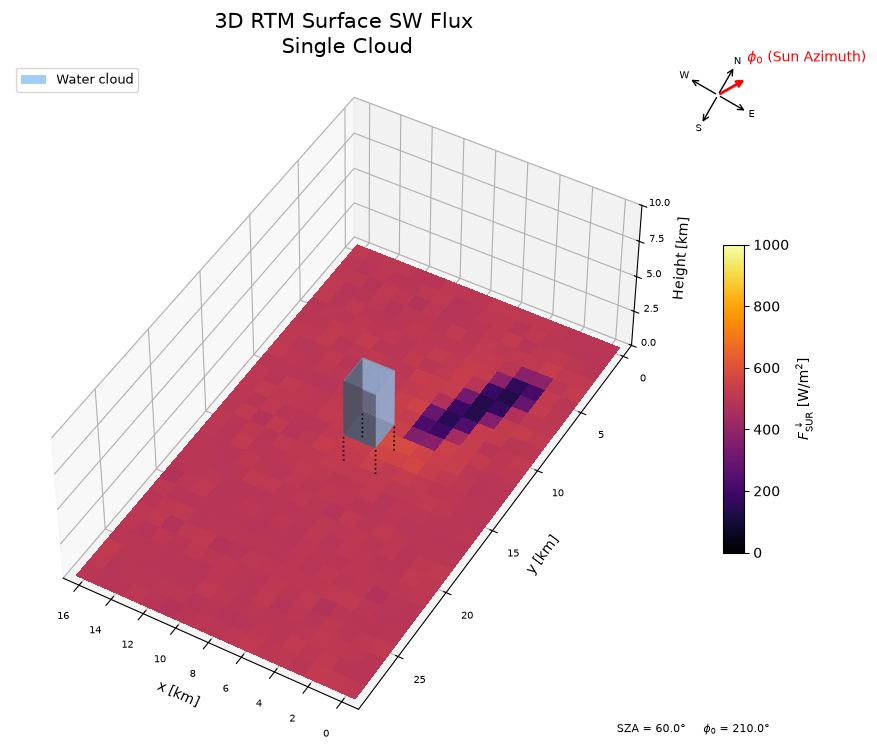

In [112]:


WANT_3D  = True      # MYSTIC or DISORT
WANT_EUP = False       # True -> eup -> TOA    False -> edir+edn -> SUR

sza, phi0 = 60, 210


which_buffer = 4
Nx, Ny, _, _ = Calc3DBufferSize(None, None, which_buffer, sza, phi0)   

# Nx, Ny = 1, 1 # Default Horizontal Computaion-Domain Size                                                                                     # min / pixel   |     solar-std     |     thermal-std  
# if   which_buffer == 0 :                  buffer_str = 'MCIPA'
# elif which_buffer == 1 : Nx, Ny =  5,  5; buffer_str = 'TEST   Buffer (5 x 5)'                      #   1.5         |                   |
# elif which_buffer == 2 : Nx, Ny = 21, 21; buffer_str = '~BBR +  5 pixels-buffer  (21 x 21)'         #    4          |       ~5-8        |       ~0.5-2
# elif which_buffer == 3 : Nx, Ny = 41, 41; buffer_str = '~BBR + 35 pixels-buffer  (41 x 41)'         #    5          |       ~17         |       ~1.6
# else:buffer_str = ''

ial, iacr = Ny // 2, Nx // 2
print(f"ial = {ial}, iacr = {iacr}, which_buffer = {which_buffer}")
# if not WANT_3D: iacr = 0

# # libRadtran used phi0 rel to south, not north.
# # Add 180 deg to phi0 
# phi0 = (phi0 + 180) % 360

Nx, Ny, iacrosses, ialongs = Calc3DBufferSize(ial, iacr, which_buffer, sza, phi0)  #calculates along and cross track buffer size 



libRad = Read_EC_data(WANT_3D, WANT_EUP, ial, iacr)


solver = "3D RTM" if WANT_3D else "1D RTM"
zout   = "TOA" if WANT_EUP else "Surface"


title       = f'{solver} {zout} SW Flux \n{libRad.Name}'
pngfile     = 'FIGS/3D_RT.png'
h_max       = 10
fig_elev = 90   
fig_elev = 45

WANT_COMPASS = True
plot_3D(libRad, ial, iacr, title, h_max, fig_elev, which_buffer, WANT_COMPASS, sza, phi0)








# 3D and 1D RTM same figure

In [270]:

def plot_1D_3D_side_by_side(libRad_1D, libRad_3D, cloud_file, title="Solar flux comparison", fig_elev=30, azimuth_offset=30, sza_deg=45, phi0_deg=45, WANT_COMPASS=False, vmin=0, vmax=1000, flux_label=r"$F_{\mathrm{SUR}}^{\downarrow}$ [W/m$^2$]",):
    # Cloud-file indices are one-based; coordinates are in km.
    with open(cloud_file, "r") as f:
        Nx, Ny, Nz, flag = map(int, next(f).split())
        geometry = np.asarray(next(f).split(), dtype=float)
        dx, dy = geometry[:2]
        z_edges = geometry[2:]

        if flag != 3:
            raise ValueError("Expected cloud-file format flag 3.")
        if len(z_edges) != Nz + 1:
            raise ValueError("Cloud file must contain Nz + 1 height edges.")
        if dx <= 0 or dy <= 0 or np.any(np.diff(z_edges) <= 0):
            raise ValueError("Cell sizes and height increments must be positive.")

        cloud_mask = np.zeros((Nx, Ny, Nz), dtype=bool)

        for line in f:
            if not line.strip():
                continue
            ix, iy, iz, wc, reff = line.split()
            ix, iy, iz = int(ix) - 1, int(iy) - 1, int(iz) - 1

            if not (0 <= ix < Nx and 0 <= iy < Ny and 0 <= iz < Nz):
                raise ValueError(f"Cloud index outside domain: {line.strip()}")

            cloud_mask[ix, iy, iz] = float(wc) > 0

    flux_1D = np.ma.asarray(libRad_1D.solar_eup, dtype=float).filled(np.nan)
    flux_3D = np.ma.asarray(libRad_3D.solar_eup, dtype=float).filled(np.nan)

    if flux_1D.shape != (Nx * Ny,):
        raise ValueError(
            f"Expected 1D flux shape {(Nx * Ny,)}, got {flux_1D.shape}."
        )
    if flux_3D.shape != (1, Nx, Ny):
        raise ValueError(
            f"Expected 3D flux shape {(1, Nx, Ny)}, got {flux_3D.shape}."
        )

    flux_1D = flux_1D.reshape(Ny, Nx).T
    flux_3D = flux_3D[0]

    x_edges = (np.arange(Nx + 1) - 0.5) * dx
    y_edges = (np.arange(Ny + 1) - 0.5) * dy

    X, Y = np.meshgrid(x_edges, y_edges, indexing="ij")
    surface_z = z_edges[0]
    Z = np.full(X.shape, surface_z)

    Xv, Yv, Zv = np.meshgrid(
        x_edges, y_edges, z_edges, indexing="ij"
    )

    norm = Normalize(vmin=vmin, vmax=vmax)
    color_map = plt.get_cmap(cmap)

    fig = plt.figure(figsize=(15, 8), layout="constrained")
    axes = [
        fig.add_subplot(121, projection="3d", computed_zorder=False),
        fig.add_subplot(122, projection="3d", computed_zorder=False),
    ]

    cloud_cells = np.argwhere(cloud_mask)
    height = z_edges[-1] - surface_z
    offset = np.deg2rad(azimuth_offset)

    def rotate_xy(x, y):
        return (
            x * np.cos(offset) + y * np.sin(offset),
            -x * np.sin(offset) + y * np.cos(offset),
        )

    for ax, flux, panel_title in zip(
        axes,
        (flux_1D, flux_3D),
        ("1D RTM", "3D RTM"),
    ):
        ax.plot_surface(
            X, Y, Z,
            facecolors=color_map(norm(np.ma.masked_invalid(flux))),
            rstride=1,
            cstride=1,
            linewidth=0,
            antialiased=False,
            shade=False,
            zorder=1,
        )

        grid_z = surface_z + 0.001 * height
        for x in x_edges:
            ax.plot(
                [x, x], [y_edges[0], y_edges[-1]], [grid_z, grid_z],
                color="black", linestyle=":", linewidth=0.5,
                alpha=0.4, zorder=2,
            )
        for y in y_edges:
            ax.plot(
                [x_edges[0], x_edges[-1]], [y, y], [grid_z, grid_z],
                color="black", linestyle=":", linewidth=0.5,
                alpha=0.4, zorder=2,
            )

        if cloud_cells.size:
            ax.voxels(
                Xv, Yv, Zv, cloud_mask,
                facecolors="#A2CDF7",
                alpha=0.7,
                edgecolor=None,
                zorder=3,
            )

            ix_min, iy_min, iz_min = cloud_cells.min(axis=0)
            ix_max, iy_max, _ = cloud_cells.max(axis=0)

            for x in (x_edges[ix_min], x_edges[ix_max + 1]):
                for y in (y_edges[iy_min], y_edges[iy_max + 1]):
                    ax.plot(
                        [x, x], [y, y], [surface_z, z_edges[iz_min]],
                        color="black", linestyle=":",
                        linewidth=1.2, zorder=4,
                    )

            if ax is axes[0]: ax.legend(handles=[Patch(facecolor="#A2CDF7", label="Water cloud")],loc="upper left",)

        if WANT_COMPASS and ax is axes[1]:
            compass = ax.inset_axes([0.82, 0.8, 0.16, 0.16])
            compass.axis("off")

            for label, (x, y) in {
                "N": (0, 1), "S": (0, -1),
                "W": (-1, 0), "E": (1, 0),
            }.items():
                x, y = rotate_xy(x, y)
                compass.annotate(
                    "", xy=(x, y), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", lw=1),
                )
                compass.text(
                    1.15 * x, 1.15 * y, label,
                    ha="center", va="center", fontsize=7,
                )

            phi = np.deg2rad(phi0_deg)
            sx, sy = rotate_xy(-1.8 * np.sin(phi), -1.8 * np.cos(phi))
            compass.annotate(
                "", xy=(sx, sy), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", lw=2, color="red"),
            )
            compass.set(
                xlim=(-2.2, 2.2), ylim=(-2.2, 2.2), aspect="equal"
            )

        # if ax is axes[1]:
        add_solar_geometry(
            ax,
            x_edges,
            y_edges,
            surface_z,
            height,
            sza_deg=60,
            phi0_deg=210,
        )

        ax.set_title(panel_title, fontsize=FONTSIZE)
        ax.set_xlabel("x [km]", fontsize=INFOSIZE)
        ax.set_ylabel("y [km]", fontsize=INFOSIZE)
        ax.set_zlabel("Height [km]", fontsize=INFOSIZE)
        ax.set_xlim(x_edges[0], x_edges[-1])
        ax.set_ylim(y_edges[0], y_edges[-1])
        ax.set_zlim(surface_z, z_edges[-1])
        ax.set_box_aspect((Nx * dx, Ny * dy, height))
        ax.view_init(elev=fig_elev, azim=90 + azimuth_offset)
        ax.grid(True)

    mappable = ScalarMappable(norm=norm, cmap=color_map)
    colorbar = fig.colorbar(mappable, ax=axes, shrink=0.6, pad=0.04)
    colorbar.set_label(flux_label, fontsize=INFOSIZE)
    colorbar.ax.tick_params(labelsize=INFOSIZE)
    # # Add info to plot
    # ax.text2D(0.90,0,
    #     f"SZA = {sza_deg:.1f}°     "+ r"$\phi_0$"+ f" = {phi0_deg:.1f}°",
    #     transform=ax.transAxes,fontsize=INFOSIZE*.8,verticalalignment="bottom",)
    
    
    plt.savefig("FIGS/Visualization_RT.png")
    plt.show()
    return 


def add_solar_geometry(ax, x_edges, y_edges, surface_z, height, sza_deg=60, phi0_deg=210):
    x_span, y_span = np.ptp(x_edges), np.ptp(y_edges)
    theta, phi = np.deg2rad([sza_deg, phi0_deg % 360])
    sun_xy = -np.array([np.sin(phi), np.cos(phi)])

    length = min(0.3 * min(x_span, y_span), 0.6 * height * np.tan(theta))
    ray_height = length / np.tan(theta)
    z = surface_z + 0.005 * height
    yellow, order = "#FFD700", 30

    candidates = np.array([
        [x_edges[0] + fx * x_span, y_edges[0] + fy * y_span, z]
        for fx in (0.8, 0.7, 0.77) for fy in (0.8, 0.7, 0.77)
    ])
    px, py, _ = proj3d.proj_transform(*candidates.T, ax.get_proj())
    px = (px - px.min()) / max(np.ptp(px), 1e-12)
    py = (py - py.min()) / max(np.ptp(py), 1e-12)
    ground = candidates[np.argmin(px + py)]

    projected = ground + np.r_[length * sun_xy, 0]
    sun_point = projected + [0, 0, ray_height]
    north_tip = ground + [0, -length, 0]

    ax.quiver(*sun_point, *(ground - sun_point), color=yellow,
              linewidth=3, arrow_length_ratio=0.15,
              normalize=False, zorder=order)

    for endpoint, color, layer in (
        (projected, yellow, order),
        (ground + [0, 0, 1.25 * ray_height], "black", order + 1),
        (north_tip, "black", order + 1),
    ):
        ax.plot(*np.column_stack((ground, endpoint)), color=color,
                linestyle=":", linewidth=1, zorder=layer)

    radius_theta, radius_phi = 0.65 * ray_height, 0.50 * length
    angles = np.linspace(0, theta, 60)
    ax.plot(
        ground[0] + radius_theta * np.sin(angles) * sun_xy[0],
        ground[1] + radius_theta * np.sin(angles) * sun_xy[1],
        z + radius_theta * np.cos(angles),
        color="white", linewidth=1, zorder=order + 2,
    )

    angles_phi = np.linspace(0, phi, 100)
    ax.plot(
        ground[0] - radius_phi * np.sin(angles_phi),
        ground[1] - radius_phi * np.cos(angles_phi),
        np.full(angles_phi.shape, z),
        color="white", linewidth=1, zorder=order + 2,
    )

    theta_label = ground + 1.8 * radius_theta * np.r_[.7, .4, .5]
    phi_label = ground - 1.25 * radius_phi * np.r_[.1, -1.1, .1] #* np.array([np.sin(phi / 2), np.cos(phi / 2), 0])
    sun_label = sun_point + [0, 0, 0.08 * ray_height]

    for position, label, color, size in (
        (theta_label, fr"$\theta={sza_deg}^\circ$", "white", INFOSIZE),
        (phi_label, fr"$\phi_0={phi0_deg}^\circ$", "white", INFOSIZE),
        (north_tip, "N", "black", INFOSIZE),
        (sun_label, "Sun", "yellow", INFOSIZE),
    ):
        ax.text(*position, label, color=color,
                fontsize=size, zorder=order + 3)

Searching for libRadtran file: B:\publication_1\RESULTS_TEST\libRad_v01_disort_1D_solar_SINGLE_CLOUD_SUR.nc
Found libRadtran file: B:\publication_1\RESULTS_TEST\libRad_v01_disort_1D_solar_SINGLE_CLOUD_SUR.nc
Searching for libRadtran file: B:\publication_1\RESULTS_TEST\libRad_v01_montecarlo_3D_solar_SINGLE_CLOUD_SUR.nc
Found libRadtran file: B:\publication_1\RESULTS_TEST\libRad_v01_montecarlo_3D_solar_SINGLE_CLOUD_SUR.nc


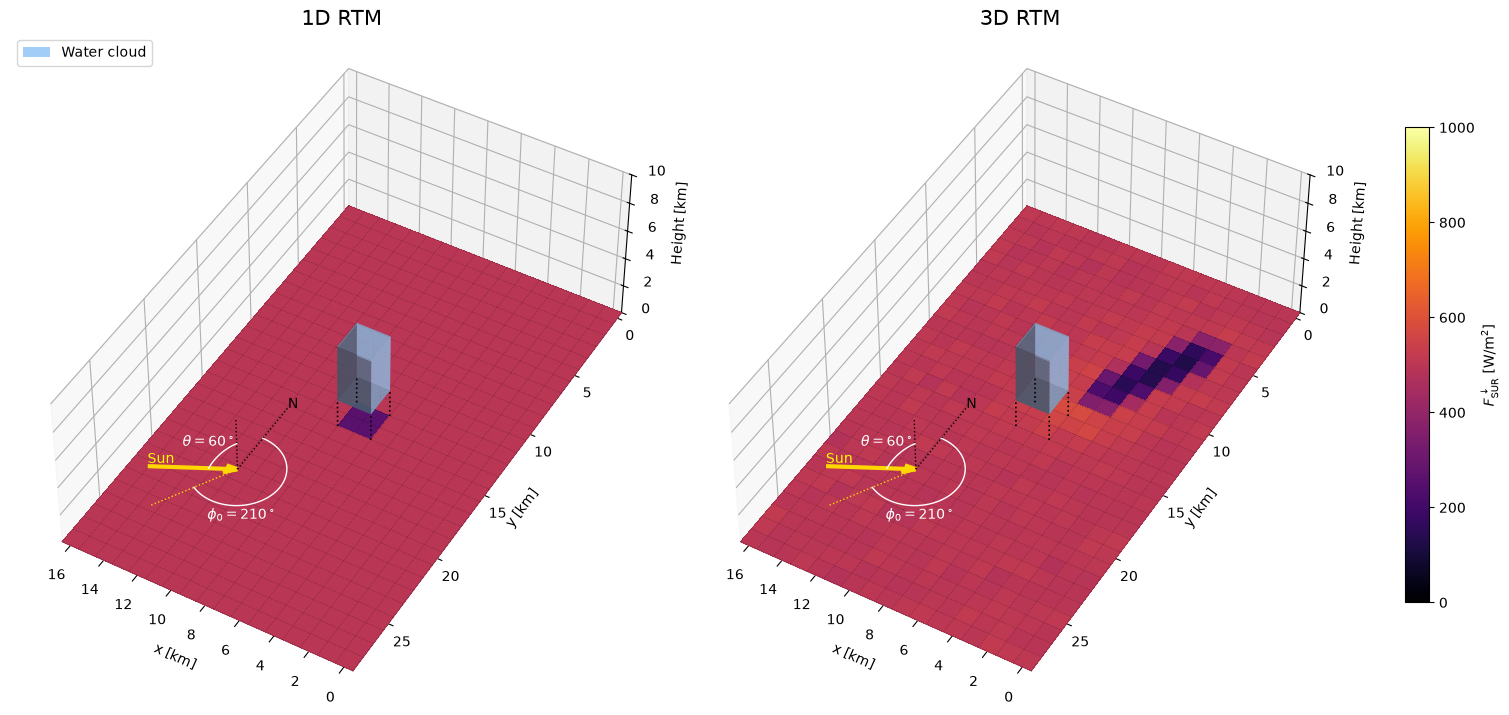

In [271]:
libRad_1D = Read_EC_data(False, WANT_EUP, ial, iacr)
libRad_3D = Read_EC_data(True, WANT_EUP, ial, iacr)


plot_1D_3D_side_by_side(
    libRad_1D,
    libRad_3D,
    cloud_file=f"tmpRTIO/tmp_{ial:04d}_wc3D.dat",
    fig_elev=45,
    azimuth_offset=30,
    sza_deg=60,
    phi0_deg=210,
    WANT_COMPASS=False,
)